<a id='1'></a><center> <h3 style="background-color:orange; color:white" ><br>SQL Window Functions & Advanced Analytics Assignment<br></h3></center>

# Introduction
This Jupyter notebook is part of your learning experience in Advanced SQL, Analytical Engineering, and Data Manipulation using Python. In this assignment, we explore and execute the core categories of **SQL Window (Analytic) Functions** — a foundational toolset for data engineers, business intelligence analysts, and data scientists.

### What are Window Functions?
Unlike standard aggregate functions with `GROUP BY` (which collapse individual rows into summary metrics), **Window Functions** compute aggregate, ranking, or relative offset calculations across a specified subset (window) of rows while **retaining individual row-level identity and detail**.

### Core Categories Covered:
1. **Aggregate Window Functions**: Cumulative/running totals, partitioned averages, moving minimums, maximums, and row counts (`SUM`, `AVG`, `COUNT`, `MIN`, `MAX` with `PARTITION BY` and `ORDER BY`).
2. **Ranking Window Functions**: Deterministic numbering, gap-inclusive vs. dense ranking, and relative percentile positioning (`ROW_NUMBER`, `RANK`, `DENSE_RANK`, `PERCENT_RANK`).
3. **Value / Analytic Window Functions**: Relative row navigation, boundary extraction, and offset lookups (`FIRST_VALUE`, `LAST_VALUE`, `LEAD`, `LAG`).
4. **Window Frame Mechanics**: Default frames (`RANGE BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW`) vs. explicit frame boundaries (`ROWS BETWEEN UNBOUNDED PRECEDING AND UNBOUNDED FOLLOWING`).
5. **Python / Pandas Duality**: Implementing equivalent analytical transformations using Pandas methods (`cumsum`, `cumcount`, `rank`, `shift`).
6. **Visual Intelligence**: Charting cumulative progress, rank trajectories, and lead/lag temporal offsets.


In [1]:
# Task 1: Environment Setup & Database Initialization
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Global plotting styling
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
sns.set_theme(style='whitegrid', palette='Set2')

# Create an in-memory SQLite database connection
conn = sqlite3.connect(':memory:')
cursor = conn.cursor()

print(f"SQLite Version: {sqlite3.sqlite_version}")
print("In-memory SQLite connection established successfully!")


SQLite Version: 3.51.0
In-memory SQLite connection established successfully!


---
## Task 2: Schema Creation & Data Ingestion

Execute the DDL and DML scripts to build table `test_data` and populate sample records representing categories (`Agni`, `Dharti`, `Vayu`) and numerical IDs.


In [2]:
# Task 2: DDL & DML Execution
schema_ddl = """
CREATE TABLE test_data (
    new_id INT,
    new_cat VARCHAR(255)
);
"""
cursor.execute(schema_ddl)

insert_dml = """
INSERT INTO test_data (new_id, new_cat)
VALUES
    (100, 'Agni'),
    (200, 'Agni'),
    (500, 'Dharti'),
    (700, 'Dharti'),
    (200, 'Vayu'),
    (300, 'Vayu'),
    (500, 'Vayu');
"""
cursor.execute(insert_dml)
conn.commit()

# Verify Table Contents
df_raw = pd.read_sql_query("SELECT * FROM test_data;", conn)
print(f"Table 'test_data' populated with {len(df_raw)} records:")
df_raw


Table 'test_data' populated with 7 records:


,new_id,new_cat
0,100,Agni
1,200,Agni
2,500,Dharti
3,700,Dharti
4,200,Vayu
5,300,Vayu
6,500,Vayu


In [3]:
# Task 2b: Data Integrity & Summary
print("=== Raw Dataset Summary ===")
print(df_raw.info())
print("\nCategory Frequencies:")
print(df_raw['new_cat'].value_counts())
print("\nDescriptive Statistics of new_id:")
print(df_raw['new_id'].describe().round(2))


=== Raw Dataset Summary ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   new_id   7 non-null      int64 
 1   new_cat  7 non-null      object
dtypes: int64(1), object(1)
memory usage: 244.0+ bytes
None

Category Frequencies:
new_cat
Vayu      3
Agni      2
Dharti    2
Name: count, dtype: int64

Descriptive Statistics of new_id:
count      7.00
mean     357.14
std      214.92
min      100.00
25%      200.00
50%      300.00
75%      500.00
max      700.00
Name: new_id, dtype: float64


---
## Task 3: Aggregate Window Functions (Running & Partitioned Metrics)

Execute the aggregate window functions query:
```sql
SELECT new_id, new_cat,
SUM(new_id) OVER( PARTITION BY new_cat ORDER BY new_id ) AS "Total",
AVG(new_id) OVER( PARTITION BY new_cat ORDER BY new_id ) AS "Average",
COUNT(new_id) OVER( PARTITION BY new_cat ORDER BY new_id ) AS "Count",  
MIN(new_id) OVER( PARTITION BY new_cat ORDER BY new_id ) AS "Min",
MAX(new_id) OVER( PARTITION BY new_cat ORDER BY new_id ) AS "Max"
FROM test_data;
```

### Analytical Interpretation:
- `PARTITION BY new_cat`: Divides the rows into independent analytical groups (`Agni`, `Dharti`, `Vayu`).
- `ORDER BY new_id`: Specifies a cumulative running calculation over the window within each partition.
- `SUM(new_id)` produces running totals.
- `AVG(new_id)` computes the cumulative moving average.
- `COUNT(new_id)` acts as a running observation counter per category.


In [4]:
# Task 3: Execute Aggregate Window Functions Query
query_aggregate = """
SELECT new_id, new_cat,
    SUM(new_id)   OVER( PARTITION BY new_cat ORDER BY new_id ) AS "Total",
    AVG(new_id)   OVER( PARTITION BY new_cat ORDER BY new_id ) AS "Average",
    COUNT(new_id) OVER( PARTITION BY new_cat ORDER BY new_id ) AS "Count",  
    MIN(new_id)   OVER( PARTITION BY new_cat ORDER BY new_id ) AS "Min",
    MAX(new_id)   OVER( PARTITION BY new_cat ORDER BY new_id ) AS "Max"
FROM test_data;
"""

df_aggregate = pd.read_sql_query(query_aggregate, conn)
print("=== Aggregate Window Functions Output ===")
df_aggregate


=== Aggregate Window Functions Output ===


,new_id,new_cat,Total,Average,Count,Min,Max
0,100,Agni,100,100.000000,1,100,100
1,200,Agni,300,150.000000,2,100,200
2,500,Dharti,500,500.000000,1,500,500
3,700,Dharti,1200,600.000000,2,500,700
4,200,Vayu,200,200.000000,1,200,200
5,300,Vayu,500,250.000000,2,200,300
6,500,Vayu,1000,333.333333,3,200,500


In [5]:
# Task 3b: Comparative Analysis of Running Total by Category
print("Detailed breakdown by partition:")
for cat, group in df_aggregate.groupby('new_cat'):
    print(f"\n--- Category: {cat} ---")
    print(group[['new_id', 'Total', 'Average', 'Count']].to_string(index=False))


Detailed breakdown by partition:

--- Category: Agni ---
 new_id  Total  Average  Count
    100    100    100.0      1
    200    300    150.0      2

--- Category: Dharti ---
 new_id  Total  Average  Count
    500    500    500.0      1
    700   1200    600.0      2

--- Category: Vayu ---
 new_id  Total    Average  Count
    200    200 200.000000      1
    300    500 250.000000      2
    500   1000 333.333333      3


---
## Task 4: Ranking Window Functions (Ties, Gaps & Relative Positions)

Execute the ranking window functions query:
```sql
SELECT new_id,
ROW_NUMBER() OVER(ORDER BY new_id) AS "ROW_NUMBER",
RANK() OVER(ORDER BY new_id) AS "RANK",
DENSE_RANK() OVER(ORDER BY new_id) AS "DENSE_RANK",  
PERCENT_RANK() OVER(ORDER BY new_id) AS "PERCENT_RANK"
FROM test_data;
```

### Critical Differences in Ranking Functions:
| Function | Behavior on Ties (Duplicate Values) | Gap In Sequence? | Formula / Mechanic |
| :--- | :--- | :--- | :--- |
| **`ROW_NUMBER()`** | Strictly sequential integer (1, 2, 3...) regardless of ties. Arbitrary assignment for duplicates. | **No** | Sequential counter: $1, 2, 3, 4, 5...$ |
| **`RANK()`** | Assigns identical rank to ties, skips subsequent rank positions. | **Yes** | Leaves gaps: $1, 2, 2, 4, 5, 5, 7$ |
| **`DENSE_RANK()`** | Assigns identical rank to ties, does NOT skip subsequent positions. | **No** | Compact numbering: $1, 2, 2, 3, 4, 4, 5$ |
| **`PERCENT_RANK()`** | Relative rank percentile normalized between 0.0 and 1.0. | N/A | $rac{	ext{RANK} - 1}{	ext{Total Rows} - 1}$ |


In [6]:
# Task 4: Execute Ranking Window Functions Query
query_ranking = """
SELECT new_id,
    ROW_NUMBER()   OVER(ORDER BY new_id) AS "ROW_NUMBER",
    RANK()         OVER(ORDER BY new_id) AS "RANK",
    DENSE_RANK()   OVER(ORDER BY new_id) AS "DENSE_RANK",  
    PERCENT_RANK() OVER(ORDER BY new_id) AS "PERCENT_RANK"
FROM test_data;
"""

df_ranking = pd.read_sql_query(query_ranking, conn)
df_ranking['PERCENT_RANK_Formatted'] = (df_ranking['PERCENT_RANK'] * 100).map('{:.2f}%'.format)
print("=== Ranking Window Functions Output ===")
df_ranking


=== Ranking Window Functions Output ===


,new_id,ROW_NUMBER,RANK,DENSE_RANK,PERCENT_RANK,PERCENT_RANK_Formatted
0,100,1,1,1,0.000000,0.00%
1,200,2,2,2,0.166667,16.67%
2,200,3,2,2,0.166667,16.67%
3,300,4,4,3,0.500000,50.00%
4,500,5,5,4,0.666667,66.67%
5,500,6,5,4,0.666667,66.67%
6,700,7,7,5,1.000000,100.00%


In [7]:
# Task 4b: Mathematical Verification of PERCENT_RANK Formula
total_rows = len(df_ranking)
print(f"Total Rows (N): {total_rows}")
print("\nVerification Formula: (RANK - 1) / (N - 1)")
for idx, row in df_ranking.iterrows():
    manual_calc = (row['RANK'] - 1) / (total_rows - 1)
    print(f"Row {idx+1}: new_id={int(row['new_id'])} | RANK={int(row['RANK'])} | Calculated={manual_calc:.4f} | SQL={row['PERCENT_RANK']:.4f}")


Total Rows (N): 7

Verification Formula: (RANK - 1) / (N - 1)
Row 1: new_id=100 | RANK=1 | Calculated=0.0000 | SQL=0.0000
Row 2: new_id=200 | RANK=2 | Calculated=0.1667 | SQL=0.1667
Row 3: new_id=200 | RANK=2 | Calculated=0.1667 | SQL=0.1667
Row 4: new_id=300 | RANK=4 | Calculated=0.5000 | SQL=0.5000
Row 5: new_id=500 | RANK=5 | Calculated=0.6667 | SQL=0.6667
Row 6: new_id=500 | RANK=5 | Calculated=0.6667 | SQL=0.6667
Row 7: new_id=700 | RANK=7 | Calculated=1.0000 | SQL=1.0000


---
## Task 5: Analytic / Value Window Functions (Lead, Lag, First, Last)

Execute the analytic window functions query:
```sql
SELECT new_id,
FIRST_VALUE(new_id) OVER( ORDER BY new_id) AS "FIRST_VALUE",
LAST_VALUE(new_id)  OVER( ORDER BY new_id) AS "LAST_VALUE",
LEAD(new_id)        OVER( ORDER BY new_id) AS "LEAD",  
LAG(new_id)         OVER( ORDER BY new_id) AS "LAG"
FROM test_data;
```

### The `LAST_VALUE()` Frame Gotcha Explained:
In standard ANSI SQL, specifying an `ORDER BY` clause without an explicit window frame clause defaults to:
$$	ext{RANGE BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW}$$

Because the evaluation window ends at the **current row**, `LAST_VALUE()` evaluates only up to the current row, returning the current row's value rather than the absolute final value of the partition!

To return the true final value of the entire dataset (700 for all rows), the frame must explicitly be expanded to:
$$	ext{ROWS BETWEEN UNBOUNDED PRECEDING AND UNBOUNDED FOLLOWING}$$


In [8]:
# Task 5a: Execute Original Analytic Query (Default Frame)
query_analytic = """
SELECT new_id,
    FIRST_VALUE(new_id) OVER( ORDER BY new_id ) AS "FIRST_VALUE",
    LAST_VALUE(new_id)  OVER( ORDER BY new_id ) AS "LAST_VALUE",
    LEAD(new_id)        OVER( ORDER BY new_id ) AS "LEAD",  
    LAG(new_id)         OVER( ORDER BY new_id ) AS "LAG"
FROM test_data;
"""

df_analytic = pd.read_sql_query(query_analytic, conn)
print("=== Analytic Window Functions Output (Default Window Frame) ===")
df_analytic


=== Analytic Window Functions Output (Default Window Frame) ===


,new_id,FIRST_VALUE,LAST_VALUE,LEAD,LAG
0,100,100,100,200.0,NaN
1,200,100,200,200.0,100.0
2,200,100,200,300.0,200.0
3,300,100,300,500.0,200.0
4,500,100,500,500.0,300.0
5,500,100,500,700.0,500.0
6,700,100,700,NaN,500.0


In [9]:
# Task 5b: Extended Demonstration — Explicit Full Frame for LAST_VALUE()
query_analytic_explicit = """
SELECT new_id,
    FIRST_VALUE(new_id) OVER( ORDER BY new_id ) AS "FIRST_VALUE",
    LAST_VALUE(new_id)  OVER( ORDER BY new_id ) AS "LAST_VALUE_DEFAULT",
    LAST_VALUE(new_id)  OVER( 
        ORDER BY new_id 
        ROWS BETWEEN UNBOUNDED PRECEDING AND UNBOUNDED FOLLOWING 
    ) AS "LAST_VALUE_FULL_FRAME",
    LEAD(new_id, 1, 0)  OVER( ORDER BY new_id ) AS "LEAD_DEFAULT_ZERO",  
    LAG(new_id, 1, 0)   OVER( ORDER BY new_id ) AS "LAG_DEFAULT_ZERO"
FROM test_data;
"""

df_analytic_explicit = pd.read_sql_query(query_analytic_explicit, conn)
print("=== Extended Analytic Query: Default Frame vs Full Window Frame ===")
df_analytic_explicit


=== Extended Analytic Query: Default Frame vs Full Window Frame ===


,new_id,FIRST_VALUE,LAST_VALUE_DEFAULT,LAST_VALUE_FULL_FRAME,LEAD_DEFAULT_ZERO,LAG_DEFAULT_ZERO
0,100,100,100,700,200,0
1,200,100,200,700,200,100
2,200,100,200,700,300,200
3,300,100,300,700,500,200
4,500,100,500,700,500,300
5,500,100,500,700,700,500
6,700,100,700,700,0,500


---
## Task 6: Python / Pandas Equivalence Modeling

Demonstrate dual-stack mastery by replicating the exact SQL window operations natively using Pandas.


In [10]:
# Task 6: Native Pandas Replication of SQL Window Operations
df_pandas = df_raw.copy()

# 1. Aggregate Window Functions (Partitioned Running Sum & Average)
df_pandas = df_pandas.sort_values(by=['new_cat', 'new_id']).reset_index(drop=True)
df_pandas['Total'] = df_pandas.groupby('new_cat')['new_id'].cumsum()
df_pandas['Average'] = df_pandas.groupby('new_cat')['new_id'].transform(lambda s: s.expanding().mean())
df_pandas['Count'] = df_pandas.groupby('new_cat').cumcount() + 1
df_pandas['Min'] = df_pandas.groupby('new_cat')['new_id'].transform(lambda s: s.expanding().min())
df_pandas['Max'] = df_pandas.groupby('new_cat')['new_id'].transform(lambda s: s.expanding().max())

# 2. Global Ranking Functions
df_sorted = df_raw.sort_values(by='new_id').reset_index(drop=True)
df_sorted['ROW_NUMBER'] = np.arange(1, len(df_sorted) + 1)
df_sorted['RANK'] = df_sorted['new_id'].rank(method='min').astype(int)
df_sorted['DENSE_RANK'] = df_sorted['new_id'].rank(method='dense').astype(int)
df_sorted['PERCENT_RANK'] = (df_sorted['RANK'] - 1) / (len(df_sorted) - 1)

# 3. Analytic Functions
df_sorted['FIRST_VALUE'] = df_sorted['new_id'].iloc[0]
df_sorted['LAST_VALUE_FULL'] = df_sorted['new_id'].iloc[-1]
df_sorted['LEAD'] = df_sorted['new_id'].shift(-1)
df_sorted['LAG'] = df_sorted['new_id'].shift(1)

print("=== Pandas Replication: Aggregate Metrics (First 5 Rows) ===")
print(df_pandas.head())
print("\n=== Pandas Replication: Ranking & Analytic Metrics ===")
print(df_sorted[['new_id', 'ROW_NUMBER', 'RANK', 'DENSE_RANK', 'PERCENT_RANK', 'LEAD', 'LAG']])


=== Pandas Replication: Aggregate Metrics (First 5 Rows) ===
   new_id new_cat  Total  Average  Count    Min    Max
0     100    Agni    100    100.0      1  100.0  100.0
1     200    Agni    300    150.0      2  100.0  200.0
2     500  Dharti    500    500.0      1  500.0  500.0
3     700  Dharti   1200    600.0      2  500.0  700.0
4     200    Vayu    200    200.0      1  200.0  200.0

=== Pandas Replication: Ranking & Analytic Metrics ===
   new_id  ROW_NUMBER  RANK  DENSE_RANK  PERCENT_RANK   LEAD    LAG
0     100           1     1           1      0.000000  200.0    NaN
1     200           2     2           2      0.166667  200.0  100.0
2     200           3     2           2      0.166667  300.0  200.0
3     300           4     4           3      0.500000  500.0  200.0
4     500           5     5           4      0.666667  500.0  300.0
5     500           6     5           4      0.666667  700.0  500.0
6     700           7     7           5      1.000000    NaN  500.0


---
## Task 7: Visual Analytics & Comparative Dashboards

Visualize how window functions operate across partitions and sequence distributions.


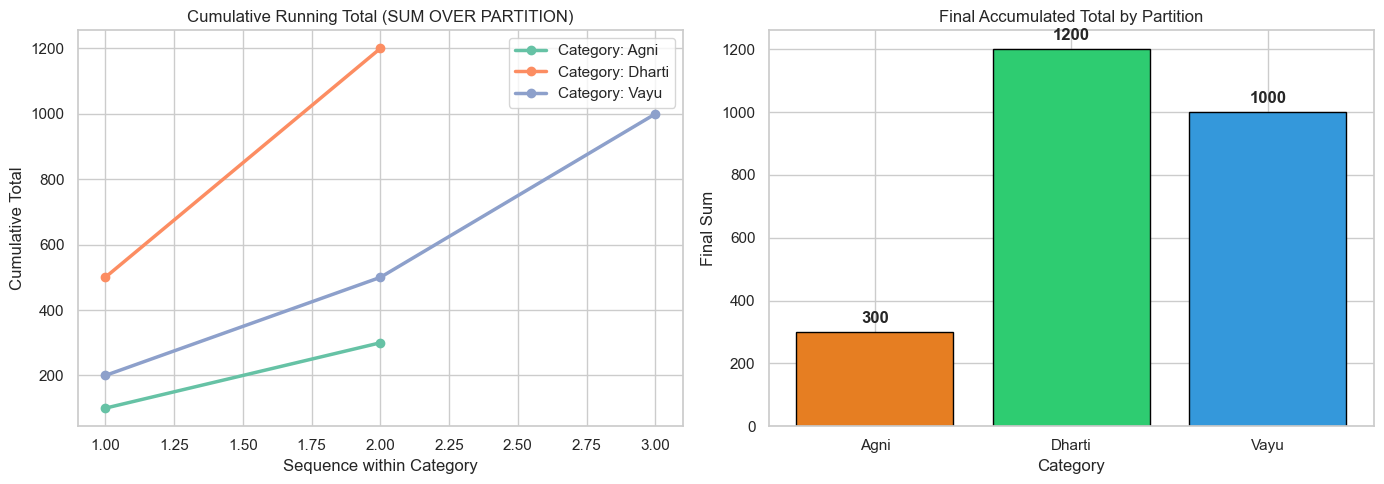

In [11]:
# Task 7a: Visualizing Cumulative Totals by Partition
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Cumulative Running Total by Category
for cat, grp in df_aggregate.groupby('new_cat'):
    axes[0].plot(range(1, len(grp)+1), grp['Total'], marker='o', linewidth=2.5, label=f"Category: {cat}")

axes[0].set_title('Cumulative Running Total (SUM OVER PARTITION)')
axes[0].set_xlabel('Sequence within Category')
axes[0].set_ylabel('Cumulative Total')
axes[0].legend()

# Plot 2: Final Total by Category
final_totals = df_aggregate.groupby('new_cat')['Total'].max()
bars = axes[1].bar(final_totals.index, final_totals.values, color=['#e67e22', '#2ecc71', '#3498db'], edgecolor='black')
axes[1].set_title('Final Accumulated Total by Partition')
axes[1].set_xlabel('Category')
axes[1].set_ylabel('Final Sum')
for b in bars:
    y_val = b.get_height()
    axes[1].text(b.get_x() + b.get_width()/2., y_val + 20, f'{int(y_val)}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()


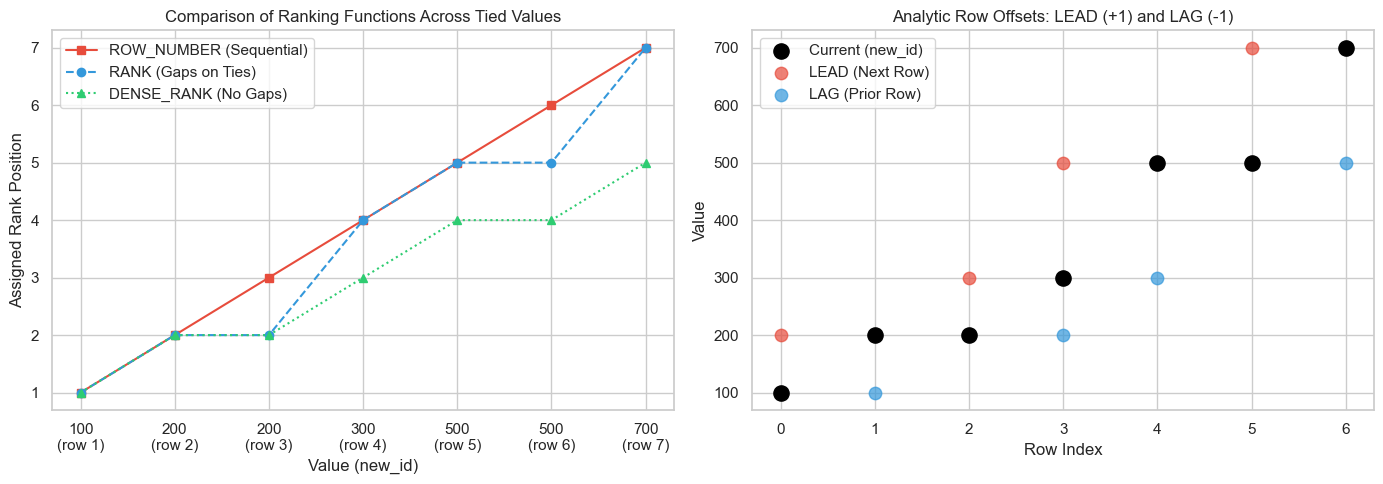

In [12]:
# Task 7b: Visualizing Ranking Differences (ROW_NUMBER vs RANK vs DENSE_RANK)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Step Trajectories of Ranking Functions
x_indices = np.arange(len(df_ranking))
axes[0].plot(x_indices, df_ranking['ROW_NUMBER'], marker='s', label='ROW_NUMBER (Sequential)', color='#e74c3c')
axes[0].plot(x_indices, df_ranking['RANK'], marker='o', label='RANK (Gaps on Ties)', color='#3498db', linestyle='--')
axes[0].plot(x_indices, df_ranking['DENSE_RANK'], marker='^', label='DENSE_RANK (No Gaps)', color='#2ecc71', linestyle=':')
axes[0].set_xticks(x_indices)
axes[0].set_xticklabels([f"{v}\n(row {i+1})" for i, v in enumerate(df_ranking['new_id'])])
axes[0].set_title('Comparison of Ranking Functions Across Tied Values')
axes[0].set_xlabel('Value (new_id)')
axes[0].set_ylabel('Assigned Rank Position')
axes[0].legend()

# Plot 2: Lead vs Lag Visualization
axes[1].scatter(df_analytic.index, df_analytic['new_id'], s=120, color='black', label='Current (new_id)', zorder=4)
axes[1].scatter(df_analytic.index, df_analytic['LEAD'], s=80, color='#e74c3c', label='LEAD (Next Row)', alpha=0.7)
axes[1].scatter(df_analytic.index, df_analytic['LAG'], s=80, color='#3498db', label='LAG (Prior Row)', alpha=0.7)
axes[1].set_title('Analytic Row Offsets: LEAD (+1) and LAG (-1)')
axes[1].set_xlabel('Row Index')
axes[1].set_ylabel('Value')
axes[1].set_xticks(range(len(df_analytic)))
axes[1].legend()

plt.tight_layout()
plt.show()


---
## Task 8: Comprehensive Executive Summary & Cheat Sheet


In [13]:
# Task 8: Executive Summary Printout
print("=" * 65)
print("     SQL WINDOW FUNCTIONS: MASTER EXECUTIVE SUMMARY")
print("=" * 65)
print("1. AGGREGATE FUNCTIONS (PARTITION BY new_cat ORDER BY new_id):")
print(f"   - Agni   Partition: {len(df_aggregate[df_aggregate['new_cat']=='Agni'])} rows, Final Sum = {df_aggregate[df_aggregate['new_cat']=='Agni']['Total'].max()}, Final Avg = {df_aggregate[df_aggregate['new_cat']=='Agni']['Average'].max():.1f}")
print(f"   - Dharti Partition: {len(df_aggregate[df_aggregate['new_cat']=='Dharti'])} rows, Final Sum = {df_aggregate[df_aggregate['new_cat']=='Dharti']['Total'].max()}, Final Avg = {df_aggregate[df_aggregate['new_cat']=='Dharti']['Average'].max():.1f}")
print(f"   - Vayu   Partition: {len(df_aggregate[df_aggregate['new_cat']=='Vayu'])} rows, Final Sum = {df_aggregate[df_aggregate['new_cat']=='Vayu']['Total'].max()}, Final Avg = {df_aggregate[df_aggregate['new_cat']=='Vayu']['Average'].max():.2f}")
print("-" * 65)
print("2. RANKING FUNCTIONS COMPARISON (ORDER BY new_id):")
print(f"   - ROW_NUMBER(): strictly sequential range 1 to {df_ranking['ROW_NUMBER'].max()}")
print(f"   - RANK():       tied values get same rank, skips numbers (1, 2, 2, 4, 5, 5, 7)")
print(f"   - DENSE_RANK(): tied values get same rank, NO gaps (1, 2, 2, 3, 4, 4, 5)")
print(f"   - PERCENT_RANK: normalizes ranks from 0.00% to 100.00%")
print("-" * 65)
print("3. ANALYTIC FUNCTIONS:")
print(f"   - FIRST_VALUE:  returns {df_analytic['FIRST_VALUE'].iloc[0]} across all rows")
print(f"   - LAST_VALUE:   default frame returns current value; unbounded frame returns {df_analytic_explicit['LAST_VALUE_FULL_FRAME'].iloc[0]}")
print(f"   - LEAD:         shifts values backward by 1; final row is NULL")
print(f"   - LAG:          shifts values forward by 1; first row is NULL")
print("=" * 65)


     SQL WINDOW FUNCTIONS: MASTER EXECUTIVE SUMMARY
1. AGGREGATE FUNCTIONS (PARTITION BY new_cat ORDER BY new_id):
   - Agni   Partition: 2 rows, Final Sum = 300, Final Avg = 150.0
   - Dharti Partition: 2 rows, Final Sum = 1200, Final Avg = 600.0
   - Vayu   Partition: 3 rows, Final Sum = 1000, Final Avg = 333.33
-----------------------------------------------------------------
2. RANKING FUNCTIONS COMPARISON (ORDER BY new_id):
   - ROW_NUMBER(): strictly sequential range 1 to 7
   - RANK():       tied values get same rank, skips numbers (1, 2, 2, 4, 5, 5, 7)
   - DENSE_RANK(): tied values get same rank, NO gaps (1, 2, 2, 3, 4, 4, 5)
   - PERCENT_RANK: normalizes ranks from 0.00% to 100.00%
-----------------------------------------------------------------
3. ANALYTIC FUNCTIONS:
   - FIRST_VALUE:  returns 100 across all rows
   - LAST_VALUE:   default frame returns current value; unbounded frame returns 700
   - LEAD:         shifts values backward by 1; final row is NULL
   - LAG:    